In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras.models import load_model
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
# Dice+CE significa a combinação das duas loss: Sparse_CategoricalCrossEntropy junto com a loss Dice

In [4]:
x_val = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/x_val.npy')
y_val = np.squeeze(np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/y_val.npy'), axis=-1)
# tirando a ultima dimensao do y, canal adicionado no processamento e para a comparação de pixels daria erro

x_test = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/test/x_test.npy')
y_test = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/test/y_test.npy')
# teste de outra base, o rotulo é da imagem inteira pois nao tem mascara real
# entao no teste nao da pra calcular IoU nem Dice

classes = ['Bacterialblight', 'Blast', 'Brownspot', 'Tungro', 'Fundo']
# classes 0-3 lesões e 4 fundo

In [5]:
# iou de uma classe, intersecao dividido pela uniao das areas da mascara prevista e da real
def iou_classe(y_true, y_pred, c):
  iou = keras.metrics.IoU(num_classes=5, target_class_ids=[c], sparse_y_true=True, sparse_y_pred=True)
  iou.update_state(y_true, y_pred)
  return float(iou.result())

In [6]:
# dice é 2 * intersecao / soma das duas mascaras, sempre fica maior que IoU
def dice_classe(y_true, y_pred, c):
  loss = keras.losses.dice((y_true == c).astype('float32'), (y_pred == c).astype('float32'))
  # a mascara real e a prevista viram 1 onde é a classe c é 0 no resto
  return float(1 - loss)

In [7]:
# no teste o rotulo é da imagem, entao a doença prevista da imagem é a que tem mais pixels na mascara prevista, o fundo nao conta
def doenca_predominante(mascara):
  contagem = np.stack([(mascara == c).sum(axis=(1, 2)) for c in range(4)], axis=1)
  # quantos pixels de cada doença tem em cada imagem
  doenca = contagem.argmax(axis=1)
  # pega a maior contagem
  doenca[contagem.sum(axis=1) == 0] = 4
  # se o modelo nao previu nenhum pixel de lesão fica 4 (sem lesão), senao o argmax daria 0 e contaria como Bacterialblight
  return doenca

In [ ]:
def avaliar(modelo):
  # validação tem mascara real, entao usamos IoU e Dice
  # para a predição das mascaras, prever tudo de uma vez estava estourando a memoria do colab, entao tive que separar em partes que vai para o predict
  # depois é concatenado os resultados
  y_pred = np.concatenate([np.argmax(modelo.predict(x_val[i:i + 100], batch_size=8), axis=-1) for i in range(0, len(x_val), 100)]).astype(np.uint8)
  # para cada i de 0 ate tamanho de x_val pulando de 100 em 100
  # preve as 100 imagens e pega a classe que tem mais pixels, para cada pixel o argmax pega a maior probabilidade de classe
  mascara_teste = np.concatenate([np.argmax(modelo.predict(x_test[i:i + 100], batch_size=8), axis=-1) for i in range(0, len(x_test), 100)])

  # calculando as metricas para cada classe
  iou = [iou_classe(y_val, y_pred, c) for c in range(4)]
  dice = [dice_classe(y_val, y_pred, c) for c in range(4)]

  # teste nao tem mascara real, a metrica é por imagem doença do rotulo da immagem contra doença predominante na mascara prevista
  y_pred_teste = doenca_predominante(mascara_teste)
  # labels 0, 1, 2, 3 deixando as 4 doenças o sem lesão nao entra na media
  resultado = {
      'iou_classe': iou,
      'dice_classe': dice,
      'acc_teste': accuracy_score(y_test, y_pred_teste),
      'f1_teste': f1_score(y_test, y_pred_teste, labels=[0, 1, 2, 3], average='macro', zero_division=0),
      'precision_teste': precision_score(y_test, y_pred_teste, labels=[0, 1, 2, 3], average=None, zero_division=0),
      'recall_teste': recall_score(y_test, y_pred_teste, labels=[0, 1, 2, 3], average=None, zero_division=0),
      'amostra_teste': mascara_teste[idx_amostra_teste],
  }
  print('IoU medio:', round(np.mean(iou), 4)) # media do IoU para todas as classes
  print('dice medio:', round(np.mean(dice), 4)) # DIce medio de todas as classes
  print('acuracia no teste:', round(resultado['acc_teste'], 4))
  print('F1 teste:', round(resultado['f1_teste'], 4)) # f1 macro, ou seja, para todas as classes
  print('Precision teste:', round(np.mean(resultado['precision_teste']), 4)) # das previsoes da classe x quantos eu acertei?
  print('Recall teste:', round(np.mean(resultado['recall_teste']), 4)) # da classe x quantos eu encontrei
  return resultado

In [9]:
idx_amostra_teste = np.random.choice(len(x_test), 3, replace=False)
# sorteia tres imagens do teste, as mesmas pra todos os modelos assim da pra comparar lado a lado

resultados = {}
# o resultado de cada modelo fica nesse dict

In [10]:
# U-Net
modelo = load_model('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/U-Net/modelo_unet.keras', compile=False)
# compile False porque so vamos prever
resul = avaliar(modelo)
resultados['U-Net'] = resul

13/13 ━━━━━━━━━━━━━━━━━━━━ 77s 2s/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 271ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 276ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 280ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 288ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 295ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 298ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 295ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 289ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 283ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 280ms/step
11/11 ━━━━━━━━━━━━━━━━━━━━ 49s 5s/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 262ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 266ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 273ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 279ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 286ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 292ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 298ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 299ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 298ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 290ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 282ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 278ms/step
13/13 ━━━━━━━━━━━━━━

In [11]:
# U-Net CE+Dice
modelo = load_model('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/U-Net/modelo_unet_dice.keras', compile=False)
resul = avaliar(modelo)
resultados['U-Net CE+Dice'] = resul

13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 407ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 282ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 290ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 298ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 304ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 308ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 304ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 294ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 286ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 280ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 278ms/step
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 381ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 262ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 260ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 258ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 259ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 258ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 259ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 260ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 261ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 266ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 270ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 275ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 280ms/step
13/13 ━━━━━━━━━━

In [ ]:
# U-NetResNet50
modelo = load_model('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/RESNET50_U-Net/modelo_unet_resnet.keras', compile=False)
resul = avaliar(modelo)
resultados['U-Net-ResNet50'] = resul

13/13 ━━━━━━━━━━━━━━━━━━━━ 13s 584ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 200ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 204ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 209ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 211ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 216ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 220ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 221ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 224ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 221ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 219ms/step
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 525ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 203ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 201ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 199ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 199ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 197ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 196ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 195ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 194ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 194ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 195ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 195ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 197ms/step
13/13 ━━━━━━━━━

In [ ]:
# U-NetResNet50 CE+Dice
modelo = load_model('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/RESNET50_U-Net/modelo_unet_resnet_dice.keras', compile=False)

resul = avaliar(modelo)
resultados['U-Net-ResNet50 CE+Dice'] = resul

13/13 ━━━━━━━━━━━━━━━━━━━━ 10s 495ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 200ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 201ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 206ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 211ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 217ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 220ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 222ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 224ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 224ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 221ms/step
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 423ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 206ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 204ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 200ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 200ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 199ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 198ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 198ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 195ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 195ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 197ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 196ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 195ms/step
13/13 ━━━━━━━━━

In [ ]:
# U-NetResNet101
modelo = load_model('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/RESNET101_U-Net/modelo_unet_resnet101.keras', compile=False)
resul = avaliar(modelo)

resultados['U-Net-ResNet101'] = resul

13/13 ━━━━━━━━━━━━━━━━━━━━ 15s 747ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 241ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 248ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 253ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 261ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 264ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 268ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 270ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 267ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 260ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 254ms/step
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 548ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 240ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 238ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 238ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 235ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 235ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 235ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 236ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 236ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 238ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 239ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 238ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 239ms/step
13/13 ━━━━━━━━━

In [ ]:
# U-NetResNet101 CE+Dice
modelo = load_model('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/RESNET101_U-Net/modelo_unet_resnet101_dice.keras', compile=False)
resul = avaliar(modelo)
resultados['U-Net-ResNet101 CE+Dice'] = resul

13/13 ━━━━━━━━━━━━━━━━━━━━ 15s 737ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 238ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 240ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 244ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 251ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 256ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 259ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 265ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 268ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 268ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 264ms/step
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 560ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 245ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 241ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 239ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 239ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 240ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 238ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 239ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 236ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 239ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 238ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 239ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 240ms/step
13/13 ━━━━━━━━━

In [ ]:
# U-NetResNet101 decoder maior CE+Dice
modelo = load_model('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/RESNET101_U-Net/modelo_unet_resnet101_decoder_maior_dice.keras', compile=False)
resul = avaliar(modelo)
resultados['U-Net-ResNet101 decoder maior CE+Dice'] = resul

13/13 ━━━━━━━━━━━━━━━━━━━━ 80s 4s/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 572ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 578ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 567ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 554ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 542ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 536ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 532ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 530ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 533ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 537ms/step
11/11 ━━━━━━━━━━━━━━━━━━━━ 38s 4s/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 534ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 556ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 583ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 599ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 581ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 555ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 538ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 526ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 522ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 522ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 525ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 529ms/step
13/13 ━━━━━━━━━━━━━━

In [17]:
# U-Net-EfficientNetB0
modelo = load_model('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/EFFICIENTNETB0_U-Net/modelo_unet_efficientnet.keras', compile=False)
resul = avaliar(modelo)
resultados['U-Net-EfficientNetB0'] = resul

13/13 ━━━━━━━━━━━━━━━━━━━━ 32s 1s/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 100ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 100ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 100ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 100ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 100ms/step
11/11 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 92ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 92ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 92ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 92ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 92ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 92

In [18]:
# U-Net-EfficientNetB0 CE+Dice
modelo = load_model('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/EFFICIENTNETB0_U-Net/modelo_unet_efficientnet_dice.keras', compile=False)
resul = avaliar(modelo)
resultados['U-Net-EfficientNetB0 CE+Dice'] = resul

13/13 ━━━━━━━━━━━━━━━━━━━━ 16s 760ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 97ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 96ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 99ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 99ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 100ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 100ms/step
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 559ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 100ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 100ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 98ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 99ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 98ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 97ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 96ms/step
13/13 ━━━━━━━━━━━━━━━━━━

In [ ]:
# resumo de cada modelo, IoU e Dice medios das quatro doenças na validação e acuracia e f1 no teste
linhas = []
for nome, r in resultados.items():
  # linhas pega o modelo e suas metricas diante os dados de teste
  linhas.append({'modelo': nome, 'iou_medio_val': np.mean(r['iou_classe']), 'dice_medio_val': np.mean(r['dice_classe']),
                 'acc_teste': r['acc_teste'], 'f1_teste': r['f1_teste']})

# adicionando ao dataframe como o nome do modelo como indice
pd.DataFrame(linhas).set_index('modelo').round(4)

,iou_medio_val,dice_medio_val,acc_teste,f1_teste
modelo,,,,
U-Net,0.7295,0.8434,0.4708,0.5436
U-Net CE+Dice,0.7344,0.8468,0.4380,0.4689
U-Net-ResNet50,0.7201,0.8371,0.5925,0.6156
U-Net-ResNet50 CE+Dice,0.7218,0.8383,0.5852,0.6056
U-Net-ResNet101,0.7217,0.8382,0.4773,0.4658
U-Net-ResNet101 CE+Dice,0.7208,0.8375,0.5490,0.5626
U-Net-ResNet101 decoder maior CE+Dice,0.7223,0.8386,0.5536,0.5799
U-Net-EfficientNetB0,0.7143,0.8331,0.5196,0.5048
U-Net-EfficientNetB0 CE+Dice,0.7142,0.8331,0.5124,0.5544


In [20]:
# iou por doença de cada modelo na validação
tabela = {}
for nome, r in resultados.items():
  tabela[nome] = r['iou_classe']
pd.DataFrame(tabela, index=classes[:4]).T.round(4)
# cada chave no dict tabela, vai ser uma coluna no dataframe
# pois aqui sera calculado o IoU de cada modelo
# o classes[:4] pega somente as lesoes
# o .T é a transposta, ou seja, vai trocar as linhas por colunas
# como resultado final o modelo terá as metricas nas colunas e seu respectivo nome na linha

,Bacterialblight,Blast,Brownspot,Tungro
U-Net,0.7588,0.7318,0.7096,0.7176
U-Net CE+Dice,0.7590,0.7424,0.7130,0.7233
U-Net-ResNet50,0.7529,0.7255,0.6981,0.7040
U-Net-ResNet50 CE+Dice,0.7512,0.7265,0.6991,0.7104
U-Net-ResNet101,0.7524,0.7263,0.6979,0.7101
U-Net-ResNet101 CE+Dice,0.7544,0.7241,0.6953,0.7092
U-Net-ResNet101 decoder maior CE+Dice,0.7532,0.7288,0.6967,0.7107
U-Net-EfficientNetB0,0.7498,0.7231,0.6846,0.6997
U-Net-EfficientNetB0 CE+Dice,0.7466,0.7185,0.6916,0.7001


In [21]:
# dice por doença de cada modelo na validação
tabela = {}
for nome, r in resultados.items():
  tabela[nome] = r['dice_classe']

pd.DataFrame(tabela, index=classes[:4]).T.round(4)

,Bacterialblight,Blast,Brownspot,Tungro
U-Net,0.8629,0.8452,0.8301,0.8356
U-Net CE+Dice,0.8630,0.8522,0.8325,0.8394
U-Net-ResNet50,0.8590,0.8409,0.8222,0.8263
U-Net-ResNet50 CE+Dice,0.8579,0.8416,0.8229,0.8307
U-Net-ResNet101,0.8587,0.8414,0.8221,0.8305
U-Net-ResNet101 CE+Dice,0.8600,0.8400,0.8202,0.8299
U-Net-ResNet101 decoder maior CE+Dice,0.8592,0.8431,0.8212,0.8309
U-Net-EfficientNetB0,0.8570,0.8393,0.8128,0.8233
U-Net-EfficientNetB0 CE+Dice,0.8549,0.8362,0.8177,0.8236


In [22]:
# precision por doença de cada modelo
tabela = {}
for nome, r in resultados.items():
  tabela[nome] = r['precision_teste']
pd.DataFrame(tabela, index=classes[:4]).T.round(4)

,Bacterialblight,Blast,Brownspot,Tungro
U-Net,0.6512,0.4022,0.8492,0.8405
U-Net CE+Dice,0.6154,0.3578,0.7967,0.7372
U-Net-ResNet50,0.7025,0.3381,0.8333,0.7838
U-Net-ResNet50 CE+Dice,0.7689,0.3184,0.8066,0.7788
U-Net-ResNet101,0.5692,0.2931,0.9253,0.5359
U-Net-ResNet101 CE+Dice,0.6239,0.2947,0.8658,0.7713
U-Net-ResNet101 decoder maior CE+Dice,0.6791,0.3044,0.8440,0.7674
U-Net-EfficientNetB0,0.5013,0.2706,0.8529,0.9157
U-Net-EfficientNetB0 CE+Dice,0.5423,0.3266,0.8745,0.9181


In [23]:
# recall por doença de cada modelo (teste)
tabela = {}
for nome, r in resultados.items():
  tabela[nome] = r['recall_teste']
pd.DataFrame(tabela, index=classes[:4]).T.round(4)

,Bacterialblight,Blast,Brownspot,Tungro
U-Net,0.2497,0.5566,0.3403,0.8813
U-Net CE+Dice,0.2854,0.6449,0.1288,0.8831
U-Net-ResNet50,0.5083,0.5413,0.4993,0.8867
U-Net-ResNet50 CE+Dice,0.4535,0.6123,0.4823,0.8867
U-Net-ResNet101,0.1885,0.5873,0.3417,0.9676
U-Net-ResNet101 CE+Dice,0.4331,0.6200,0.3561,0.9101
U-Net-ResNet101 decoder maior CE+Dice,0.3936,0.5585,0.4691,0.8903
U-Net-EfficientNetB0,0.7312,0.4088,0.1143,0.8795
U-Net-EfficientNetB0 CE+Dice,0.4242,0.5931,0.2746,0.8867


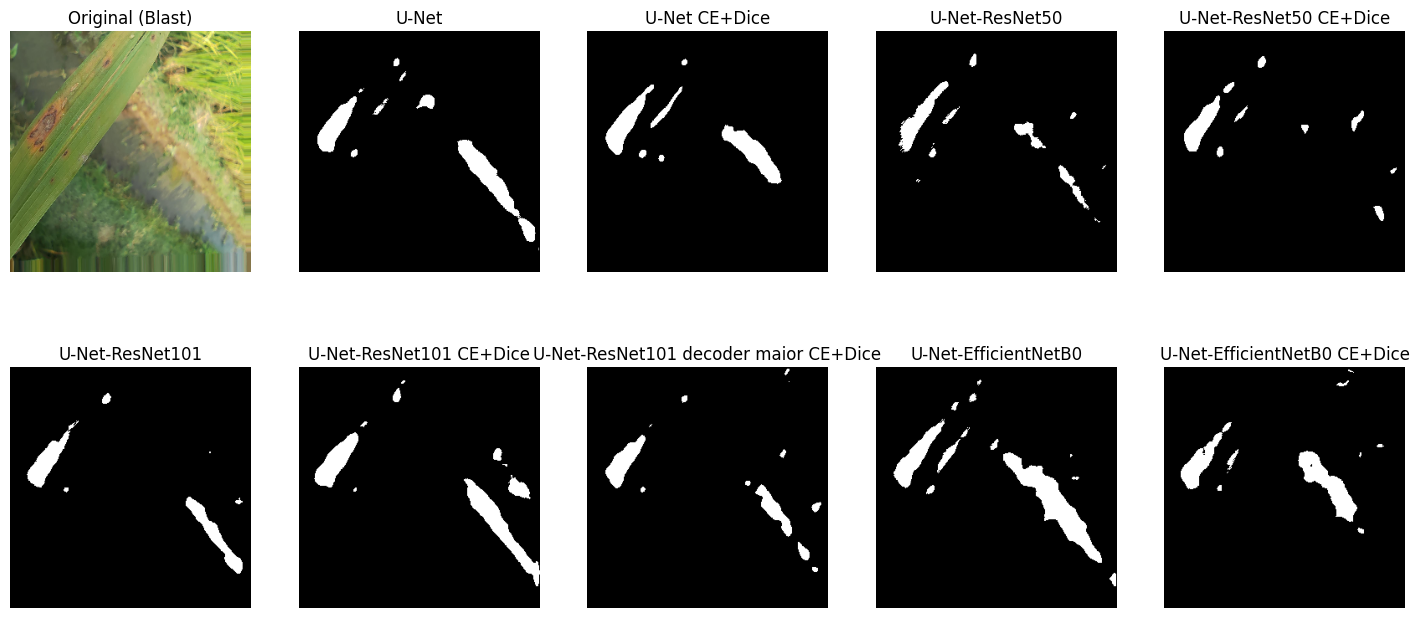

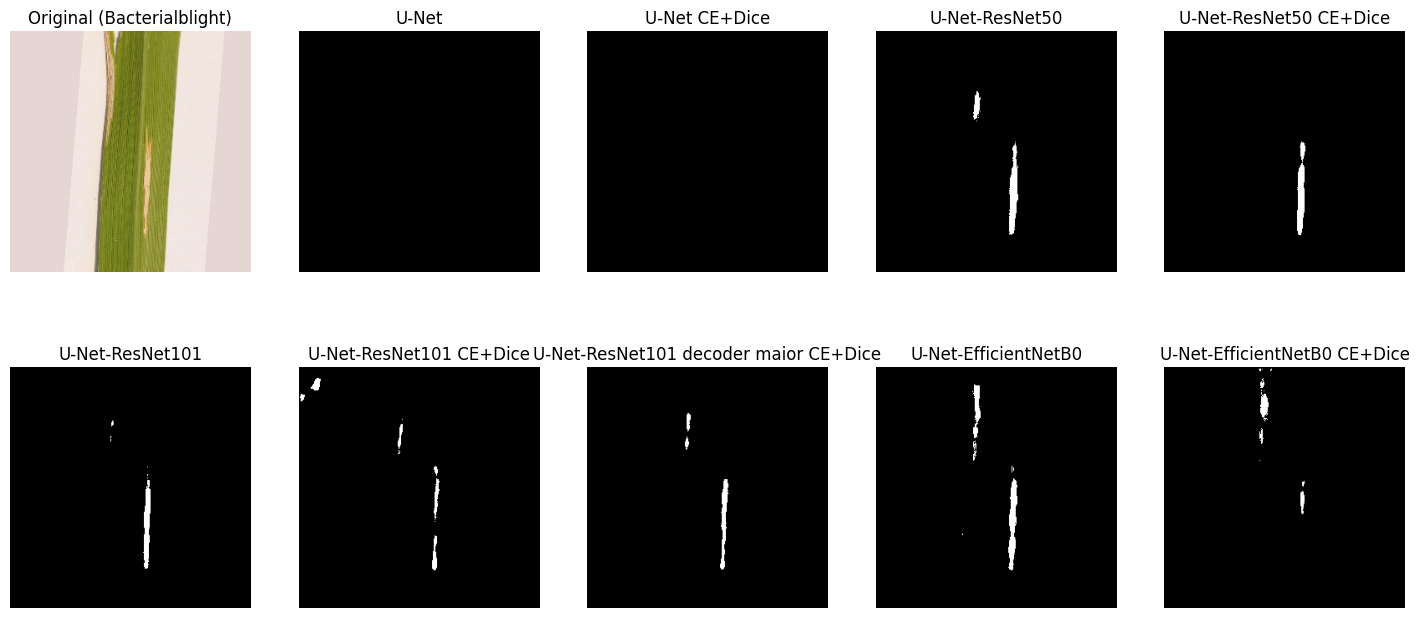

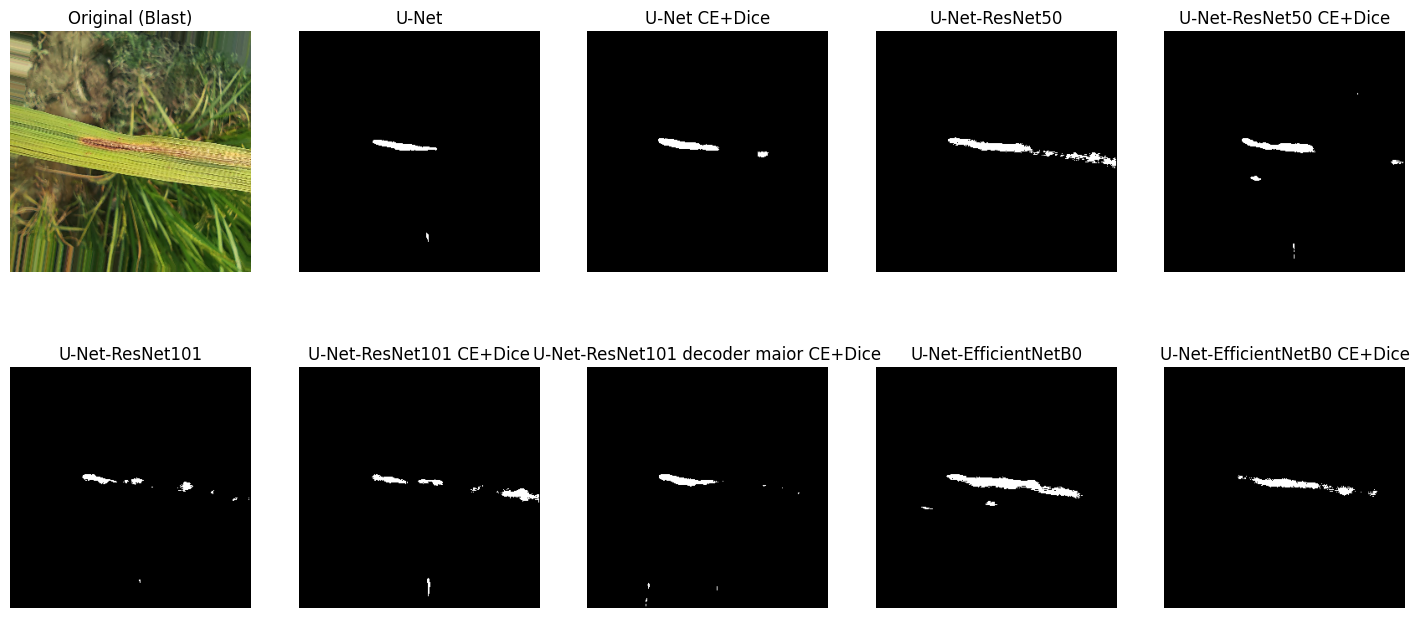

In [ ]:
# mascaras previstas no teste em preto e branco é doença preto é fundo
# nao tem mascara real, entao é a imagem original com a doença do rotulo e a previsao de cada modelo
for k, idx in enumerate(idx_amostra_teste):
  plt.figure(figsize=(18, 8))
  # figura 2x5 a primeira é a imagem original e as outras nove sao os modelos

  plt.subplot(2, 5, 1)
  plt.imshow(x_test[idx])
  plt.axis('off')
  plt.title('Origina' + classes[y_test[idx]])

  for i, nome in enumerate(resultados):
    plt.subplot(2, 5, i + 2)
    plt.imshow(resultados[nome]['amostra_teste'][k] < 4, cmap='gray')
    # < 4 deixa a mascara em preto e branco, as classes 0-3 viram branco e o fundo preto
    plt.axis('off')
    plt.title(nome)

  plt.show()